Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. Perform following tasks: 1. Pre-process the dataset. 2. Identify outliers. 3. Check the correlation. 4. Implement linear regression and random forest regression models. Evaluate the models and compare their respective scores like R2, RMSE, etc.  Dataset link: Uber Fares Dataset (Kaggle)  https://www.kaggle.com/datasets/yasserh/uber-fares-dataset

In [1]:
import pandas as pd

data = pd.read_csv(r"E:\BE_Assignments\ML\uber_csv.csv")
data

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...,...,...
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [2]:
data = data.drop(columns = ["key","Unnamed: 0","pickup_datetime"])
data = data.dropna()
data.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
import numpy as np

# pre process to remove invalid coords
coordinate_columns = [
    'pickup_latitude', 'pickup_longitude',
    'dropoff_latitude', 'dropoff_longitude'
]
# Convert coordinate columns to numeric, coercing errors to NaN
data[coordinate_columns] = data[coordinate_columns].apply(pd.to_numeric, errors='coerce')

valid_coordinates = (
    data['pickup_latitude'].between(40.5, 41.0)
    & data['dropoff_latitude'].between(40.5, 41.0)
    & data['pickup_longitude'].between(-74.3, -73.6)
    & data['dropoff_longitude'].between(-74.3, -73.6)
)
data = data.loc[valid_coordinates].copy()

data = data[(data['fare_amount'] > 0) & (data['passenger_count'].between(1, 6))].copy()

def calculate_distance(df):
    lat1, lon1 = np.radians(df['pickup_latitude']), np.radians(df['pickup_longitude'])
    lat2, lon2 = np.radians(df['dropoff_latitude']), np.radians(df['dropoff_longitude'])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

data['distance_km'] = calculate_distance(data)
data = data[data['distance_km'] > 0].copy()

In [4]:
data

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,4.475450
...,...,...,...,...,...,...,...
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1,0.112210
199996,7.5,-73.984722,40.736837,-74.006672,40.739620,1,1.875050
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2,12.850319
199998,14.5,-73.997124,40.725452,-73.983215,40.695415,1,3.539715


fare_amount 16466
passenger_count 21828
distance_km 15993


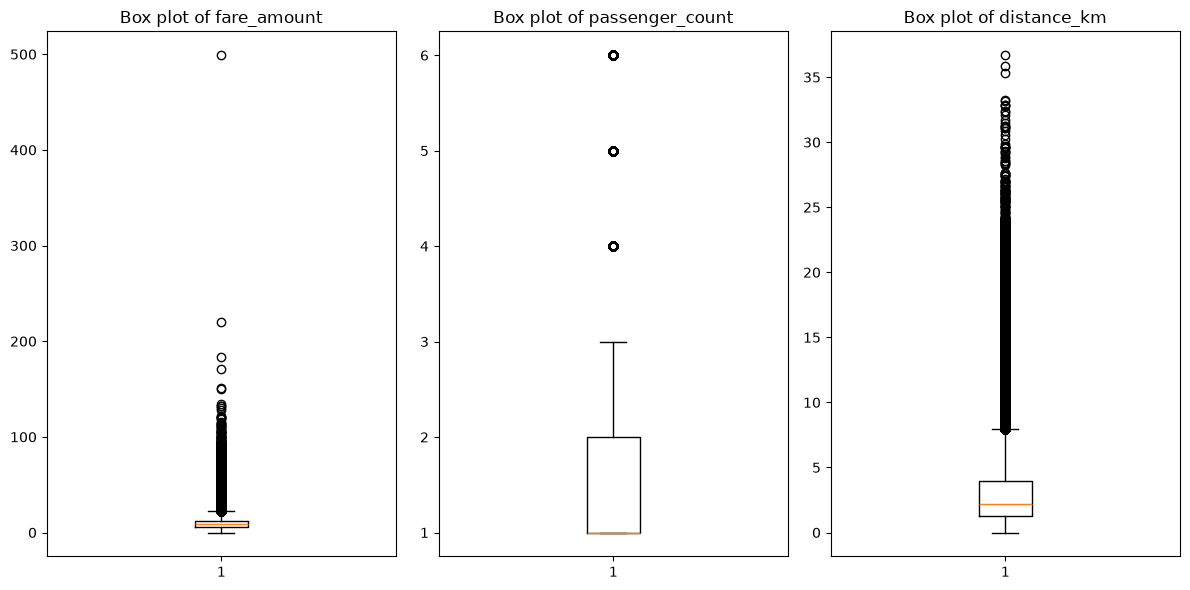

In [5]:
useful_columns = ["fare_amount","passenger_count","distance_km"]

# now identify outliers using IQR method and make box plots for each of the useful columns
def calculate_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] < lower_bound) | (df[column] > upper_bound)]

for col in useful_columns:
    print(col, len(calculate_outliers(data, col)))

# now box plot
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
for i, col in enumerate(useful_columns):
    plt.subplot(1, 3, i + 1)
    plt.boxplot(data[col])
    plt.title(f'Box plot of {col}')
plt.tight_layout()
plt.show()

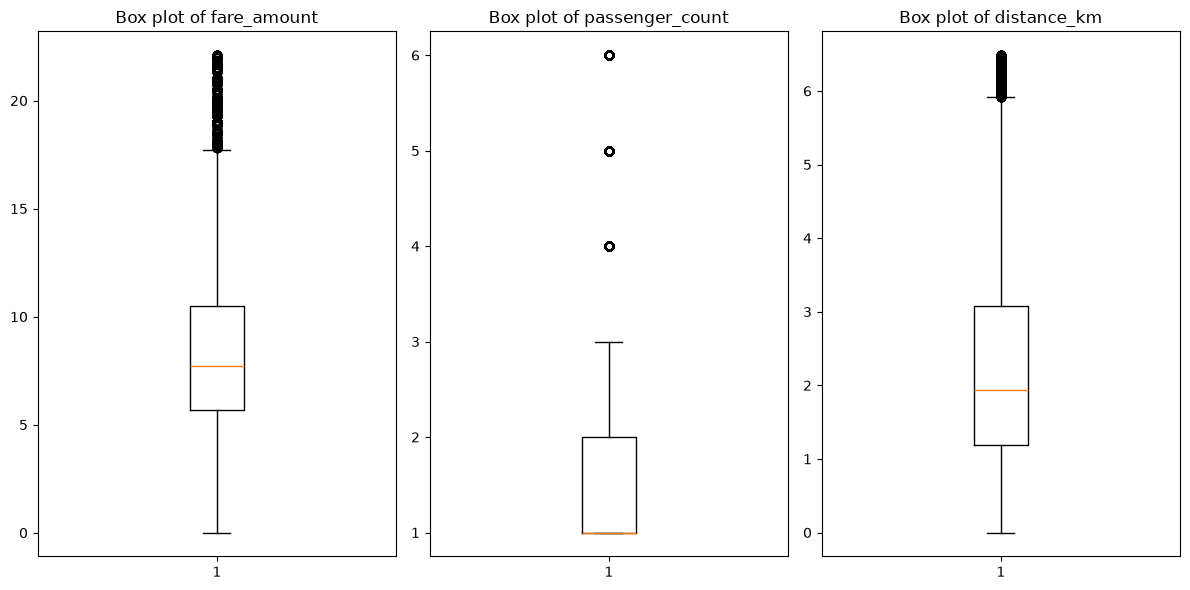

In [6]:
for col in ["fare_amount", "distance_km"]:
    data = data.drop(calculate_outliers(data, col).index)

plt.figure(figsize=(12, 6))
for i, col in enumerate(useful_columns):
    plt.subplot(1, 3, i + 1)
    plt.boxplot(data[col])
    plt.title(f'Box plot of {col}')
plt.tight_layout()
plt.show()

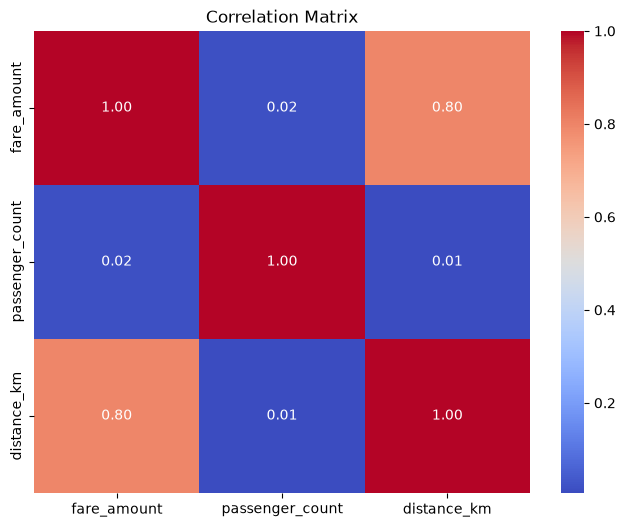

In [7]:
# correlation between columns now
import seaborn as sns

plt.figure(figsize=(8, 6))
correlation_matrix = data[useful_columns].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

In [8]:
# train models using linear and random forest regression and compare the results using R2 and RMSE 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X = data[["passenger_count", "distance_km", "pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude"]]
y = data["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regression": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "R2": r2_score(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred)
    })

pd.DataFrame(results)

,Model,R2,RMSE,MAE
0,Linear Regression,0.639749,2.222890,1.599474
1,Random Forest Regression,0.682088,2.088185,1.484410
